# **Analysis of the most popular Roblox games in 2024**


# The objective of this analysis is to:

- Compare the popularity of the top 1000 most popular Roblox

- To see how the rating of a game relates to it's popularity

- To see how player retention (via favouriting) relates to a games popularity

In [271]:
import pandas as pd

We will be working with the following data source


[Dataset Source](https://www.kaggle.com/datasets/biggiefats/roblox-games-dataset)

CONTENT

The data does not include the history of player count for the games, such as whether it is a long running game or recently made game that has rapidly gained popularity. This can be generally determined from comparing the /active player count to the total number of visits.

When a game is created is not a good measure of how long a game has been avaiable for due to time it might have spent in development or if it is a reupload of a pre-existing game.

This dataset was also taken in October, so some games had a Halloween update.

# 📘 Dataset Column Information

| Column Name | Description |
|---|---|
| **Rank** | Rank of the game on the leaderboard, based on total current players. |
| **Name** | Name of the game on Roblox. |
| **Active** | Number of active players currently playing the game at the time of recording. |
| **Visits** | Total number of visits the game has received. |
| **Favourites** | Total number of users who have favourited the game. |
| **Likes** | Total number of likes the game has received. |
| **Dislikes** | Total number of dislikes the game has received. |
| **Rating** | Like-to-dislike ratio of the game, representing the proportion of positive ratings relative to negative ratings. |

In [272]:
# read and import dataset
df = pd.read_csv("roblox_games.csv",encoding="utf-8")

In [273]:
df

,Rank,Name,Active,Visits,Favourites,Likes,Dislikes,Rating
0,#1,Blox Fruits,"483,372","41,346,317,182","13,574,097","8,521,670","676,846",92.64
1,#2,Brookhaven 🏡RP,"474,141","55,635,148,446","22,117,653","6,108,763","955,845",86.47
2,#3,Dress To Impress 💜,"297,764","3,876,511,994","3,182,036","2,042,092","188,403",91.55
3,#4,PETS GO! ✨ [NEW],"172,411","145,691,211","199,254","275,267","20,140",93.18
4,#5,Murder Mystery 2,"159,531","18,310,453,247","19,306,585","8,001,198","786,705",91.05
...,...,...,...,...,...,...,...,...
995,#996,[MOBILE/CONSOLE FIXED - BETA] The Time of Ninja,706,"5,136,808","80,497","25,291","2,841",89.90
996,#997,TEAM BORRY PRISON BREAKOUT!👮 [TEAMWORK OBBY],705,"68,323,047","15,351","1,397",586,70.45
997,#998,[👻HALLOWEEN] ADC DANCE STUDIO,704,"11,811,628","8,996","4,344",429,91.01
998,#999,🏈 Field Goal Simulator,703,"43,992,091","411,025","37,371","6,273",85.63


In [274]:
# Checking the column types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Rank        1000 non-null   object 
 1   Name        1000 non-null   object 
 2   Active      1000 non-null   object 
 3   Visits      1000 non-null   object 
 4   Favourites  1000 non-null   object 
 5   Likes       1000 non-null   object 
 6   Dislikes    1000 non-null   object 
 7   Rating      1000 non-null   float64
dtypes: float64(1), object(7)
memory usage: 62.6+ KB


We need to convert the columns featuring numbers into integers

In [275]:
column_names = ['Active', 'Visits', 'Favourites', 'Likes', 'Dislikes']

for name in column_names:
  df[name] = df[name].str.replace(',', '').astype(int)

df['Rank'] = df['Rank'].str.replace('#', '').astype(int)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Rank        1000 non-null   int64  
 1   Name        1000 non-null   object 
 2   Active      1000 non-null   int64  
 3   Visits      1000 non-null   int64  
 4   Favourites  1000 non-null   int64  
 5   Likes       1000 non-null   int64  
 6   Dislikes    1000 non-null   int64  
 7   Rating      1000 non-null   float64
dtypes: float64(1), int64(6), object(1)
memory usage: 62.6+ KB


In [276]:
# the rating is already calculated, but we might as well recalculate it and express it more precisely
df['Rating'] = df['Likes'].multiply(100).div(
    df['Likes'] + df['Dislikes']
).fillna(0)

df

,Rank,Name,Active,Visits,Favourites,Likes,Dislikes,Rating
0,1,Blox Fruits,483372,41346317182,13574097,8521670,676846,92.641791
1,2,Brookhaven 🏡RP,474141,55635148446,22117653,6108763,955845,86.469950
2,3,Dress To Impress 💜,297764,3876511994,3182036,2042092,188403,91.553310
3,4,PETS GO! ✨ [NEW],172411,145691211,199254,275267,20140,93.182287
4,5,Murder Mystery 2,159531,18310453247,19306585,8001198,786705,91.047864
...,...,...,...,...,...,...,...,...
995,996,[MOBILE/CONSOLE FIXED - BETA] The Time of Ninja,706,5136808,80497,25291,2841,89.901180
996,997,TEAM BORRY PRISON BREAKOUT!👮 [TEAMWORK OBBY],705,68323047,15351,1397,586,70.448815
997,998,[👻HALLOWEEN] ADC DANCE STUDIO,704,11811628,8996,4344,429,91.011942
998,999,🏈 Field Goal Simulator,703,43992091,411025,37371,6273,85.626890


In [277]:
# Check for duplicate game names
counts = df['Name'].value_counts()
counts[counts > 1]

,count
Name,
[UPDATE 1] Skillful,2
Guts & Blackpowder [HEADLESS HORSEMAN],2
🎃 Maple Hospital,2
PETS GO MODDED! 🎃 [PUMPKIN],2
[🎃] Skateboard Obby,2
[NEW STYLES] fight in a school,2
Kitten Game 🐾,2
Boxing Beta! 🥊,2
[🔥 UPD] Skibidi Tower Defense,2


Some games seem to have the same name, we should check if they are actually the same game or not.

In [278]:
mask = df['Name'].duplicated(keep=False)

df.loc[mask, :]

,Rank,Name,Active,Visits,Favourites,Likes,Dislikes,Rating
120,121,Southwest Florida Beta,6394,621582028,1644439,630771,70758,89.913746
121,122,Theme Park Tycoon 2,6299,1336714920,5783445,1906384,244855,88.617955
122,123,Regretevator [ ELEVATOR SIMULATOR ],6258,111875165,606060,226285,22197,91.066959
123,124,[PAGANI] Vehicle Legends 🏎️ CARS!,6211,1539051510,2262778,1023770,70590,93.549655
124,125,Gym Star Simulator[NEW TRAINER💪],6188,48128043,99671,50339,3220,93.987939
125,126,[🎃] Twilight Daycare!,6159,2321070461,1967230,750913,92459,89.036985
126,127,👁️untitled tag game👁️ [DOORS!],6092,174769187,453031,325376,31200,91.250112
127,128,💜 MeepCity 💜,6043,16094272517,14787935,2857706,483318,85.533836
128,129,Hide and Seek Extreme,5992,2904881095,6444745,881381,86547,91.058529
129,130,[W49] Obby But You’re On a Bike,5940,1407316033,5708158,773710,236023,76.625207


FORTLINE seems to be the only name that belongs to 2 distinct games, the rest seems like duplicate rows.

In [279]:
# Remove duplicate rows
cleaned_df = df.drop_duplicates().copy()
cleaned_df.reset_index(drop=True, inplace=True)

cleaned_df

,Rank,Name,Active,Visits,Favourites,Likes,Dislikes,Rating
0,1,Blox Fruits,483372,41346317182,13574097,8521670,676846,92.641791
1,2,Brookhaven 🏡RP,474141,55635148446,22117653,6108763,955845,86.469950
2,3,Dress To Impress 💜,297764,3876511994,3182036,2042092,188403,91.553310
3,4,PETS GO! ✨ [NEW],172411,145691211,199254,275267,20140,93.182287
4,5,Murder Mystery 2,159531,18310453247,19306585,8001198,786705,91.047864
...,...,...,...,...,...,...,...,...
975,996,[MOBILE/CONSOLE FIXED - BETA] The Time of Ninja,706,5136808,80497,25291,2841,89.901180
976,997,TEAM BORRY PRISON BREAKOUT!👮 [TEAMWORK OBBY],705,68323047,15351,1397,586,70.448815
977,998,[👻HALLOWEEN] ADC DANCE STUDIO,704,11811628,8996,4344,429,91.011942
978,999,🏈 Field Goal Simulator,703,43992091,411025,37371,6273,85.626890


In [280]:
# Update the ranks
cleaned_df['Rank'] = cleaned_df.index + 1
cleaned_df

,Rank,Name,Active,Visits,Favourites,Likes,Dislikes,Rating
0,1,Blox Fruits,483372,41346317182,13574097,8521670,676846,92.641791
1,2,Brookhaven 🏡RP,474141,55635148446,22117653,6108763,955845,86.469950
2,3,Dress To Impress 💜,297764,3876511994,3182036,2042092,188403,91.553310
3,4,PETS GO! ✨ [NEW],172411,145691211,199254,275267,20140,93.182287
4,5,Murder Mystery 2,159531,18310453247,19306585,8001198,786705,91.047864
...,...,...,...,...,...,...,...,...
975,976,[MOBILE/CONSOLE FIXED - BETA] The Time of Ninja,706,5136808,80497,25291,2841,89.901180
976,977,TEAM BORRY PRISON BREAKOUT!👮 [TEAMWORK OBBY],705,68323047,15351,1397,586,70.448815
977,978,[👻HALLOWEEN] ADC DANCE STUDIO,704,11811628,8996,4344,429,91.011942
978,979,🏈 Field Goal Simulator,703,43992091,411025,37371,6273,85.626890


## All duplicate entries have been removed

In [281]:
print(cleaned_df['Favourites'].mean()/cleaned_df['Active'].mean())

238.07683747308968


We now need to calculate the following fields:

- active_per_million_visits: The number of active players divided by the total number of visits in millions. This provides a rough measure of current player activity relative to a game's cumulative traffic.

- active_to_favourites: The number of active players divided by total favourites, expressed as a percentage. This roughly measures how much of the established playerbase plays the game.

- favourites_per_5k_visits: The total number of favourites divided by total visits, expressed as a percentage. This helps gauge how well a game retains players. We used 5k as there are on average 200 times more Favourites than Active players

- ratings_to_favorites: The total number of ratings (likes + dislikes) divided by total favourites, expressed as a percentage. This is to analyse how impressions relate to how many people favourite the game.

- is_halloween: Whether the keyword 'Halloween' is present in the game's name (case-insensitive).

- has_square_brackets: Square brackets in a name generally indicate a recent update or temporary event in the game.

- name_length: Number of characters in the game name. Could help investigate whether naming conventions correlate with popularity.

- has_emoji: Whether the game name contains an emoji. Useful for exploring naming patterns.

- has_update_keyword: Whether the name contains keywords such as UPDATE, NEW, BETA, or UPD.


In [282]:
import re

# Ratio features (as percentages)
cleaned_df['active_per_million_visits'] = (
    cleaned_df['Active'].div(cleaned_df['Visits']).mul(1000000)
)

cleaned_df['active_to_favourites'] = (
    cleaned_df['Active'].div(cleaned_df['Favourites']).mul(100)
)

cleaned_df['favourites_per_5k_visits'] = (
    cleaned_df['Favourites'].div(cleaned_df['Visits']).mul(5000)
)

cleaned_df['ratings_to_favorites'] = (
    (cleaned_df['Likes'] + cleaned_df['Dislikes'])
    .div(cleaned_df['Favourites'])
    .mul(100)
)

# Name-based features
cleaned_df['is_halloween'] = (
    cleaned_df['Name'].str.contains('Halloween', case=False, na=False)
)

cleaned_df['has_square_brackets'] = (
    cleaned_df['Name'].str.contains(r'\[.*?\]', regex=True, na=False)
)

cleaned_df['name_length'] = cleaned_df['Name'].str.len()

# Detect emojis
emoji_pattern = re.compile(
    "["
    "\U0001F300-\U0001F5FF"
    "\U0001F600-\U0001F64F"
    "\U0001F680-\U0001F6FF"
    "\U0001F700-\U0001F77F"
    "\U0001F780-\U0001F7FF"
    "\U0001F800-\U0001F8FF"
    "\U0001F900-\U0001F9FF"
    "\U0001FA00-\U0001FAFF"
    "\U00002700-\U000027BF"
    "\U00002600-\U000026FF"
    "]"
)

cleaned_df['has_emoji'] = (
    cleaned_df['Name'].str.contains(emoji_pattern, na=False)
)

# Detect update-related keywords
update_pattern = r'\b(?:UPDATE|NEW|BETA|UPD)\b'

cleaned_df['has_update_keyword'] = (
    cleaned_df['Name'].str.contains(
        update_pattern, case=False, regex=True, na=False
    )
)

cleaned_df.head()

,Rank,Name,Active,Visits,Favourites,Likes,Dislikes,Rating,active_per_million_visits,active_to_favourites,favourites_per_5k_visits,ratings_to_favorites,is_halloween,has_square_brackets,name_length,has_emoji,has_update_keyword
0,1,Blox Fruits,483372,41346317182,13574097,8521670,676846,92.641791,11.690811,3.560988,1.641512,67.765215,False,False,11,False,False
1,2,Brookhaven 🏡RP,474141,55635148446,22117653,6108763,955845,86.469950,8.522328,2.143722,1.987741,31.941038,False,False,14,True,False
2,3,Dress To Impress 💜,297764,3876511994,3182036,2042092,188403,91.553310,76.812351,9.357657,4.104251,70.096473,False,False,18,True,False
3,4,PETS GO! ✨ [NEW],172411,145691211,199254,275267,20140,93.182287,1183.400143,86.528250,6.838230,148.256497,False,True,16,True,True
4,5,Murder Mystery 2,159531,18310453247,19306585,8001198,786705,91.047864,8.712564,0.826304,5.272012,45.517646,False,False,16,False,False


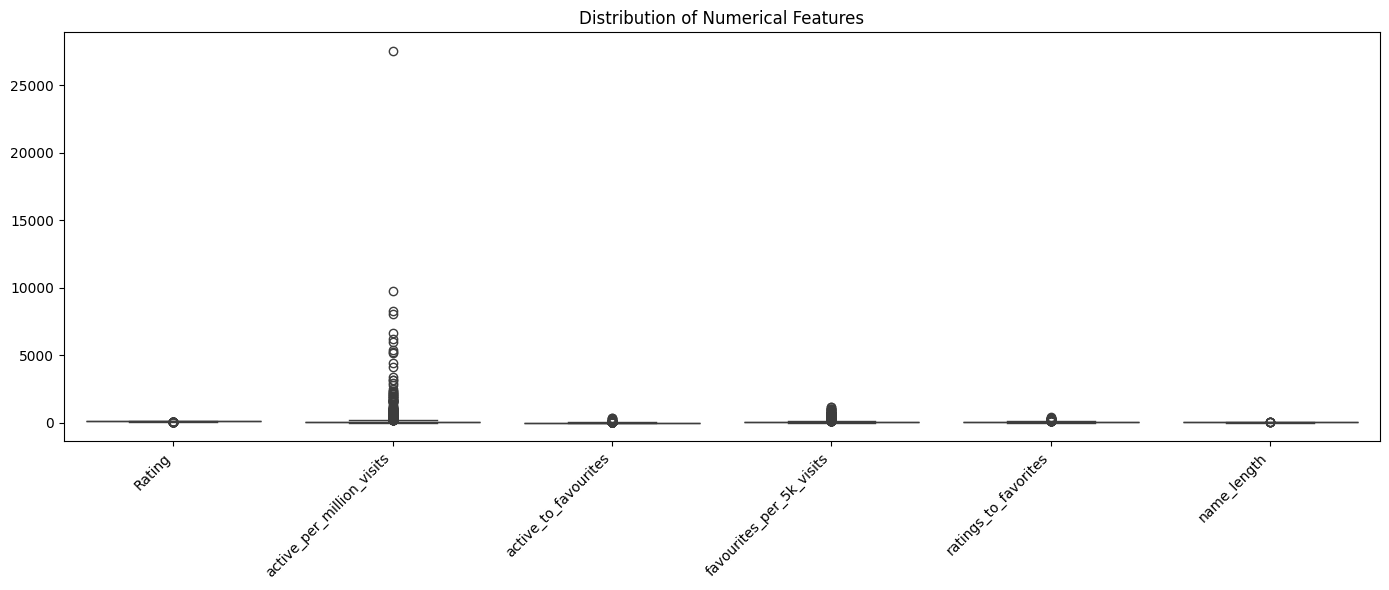

In [283]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = [
    'Rating',
    'active_per_million_visits',
    'active_to_favourites',
    'favourites_per_5k_visits',
    'ratings_to_favorites',
    'name_length'
]

plt.figure(figsize=(14, 6))

sns.boxplot(data=cleaned_df[numerical_columns])

plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

# Removing outliers
Outliers in the  active_per_million_visits column are removed, effectively removing any games that have been recently created and blown up in popularity leaving only games that have retained long term presence on the platform or have a 'normal' amount of growth.

In [284]:
Q1 = cleaned_df['active_per_million_visits'].quantile(0.25)
Q3 = cleaned_df['active_per_million_visits'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered_df = cleaned_df[
    cleaned_df['active_per_million_visits'].between(
        lower_bound, upper_bound
    )
].copy()

print(f'Removed {len(cleaned_df) - len(filtered_df)} outliers')

Removed 151 outliers


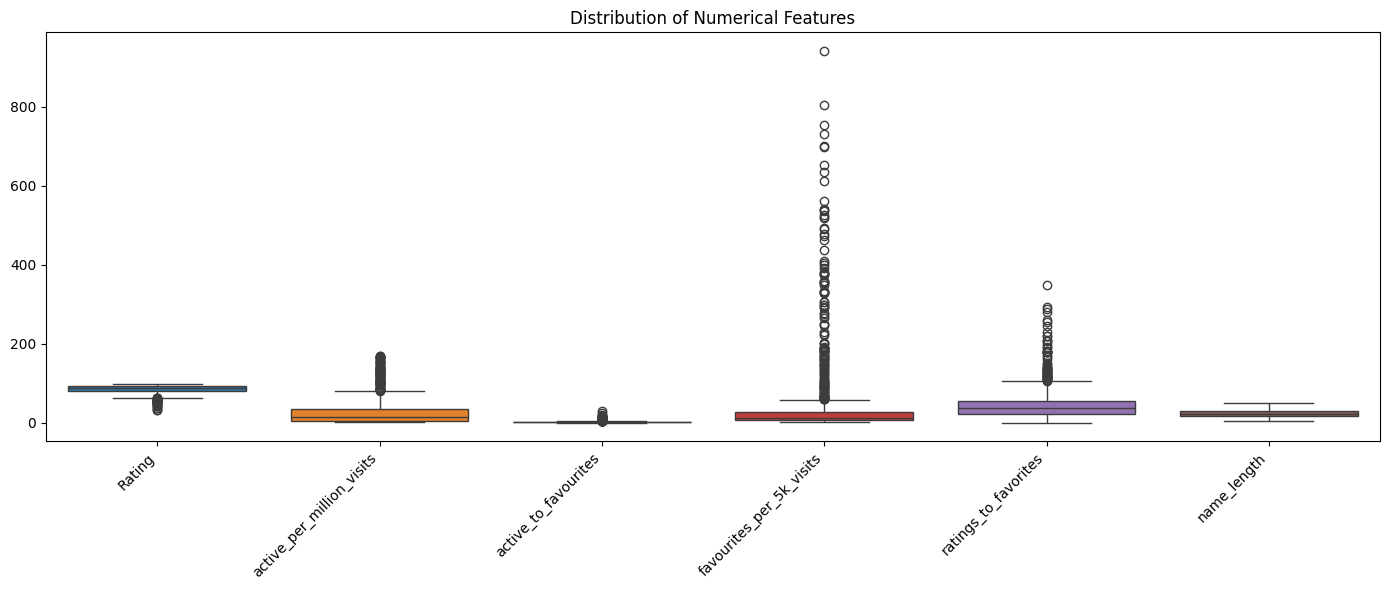

In [285]:
numerical_columns = [
    'Rating',
    'active_per_million_visits',
    'active_to_favourites',
    'favourites_per_5k_visits',
    'ratings_to_favorites',
    'name_length'
]

plt.figure(figsize=(14, 6))

sns.boxplot(data=filtered_df[numerical_columns])

plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

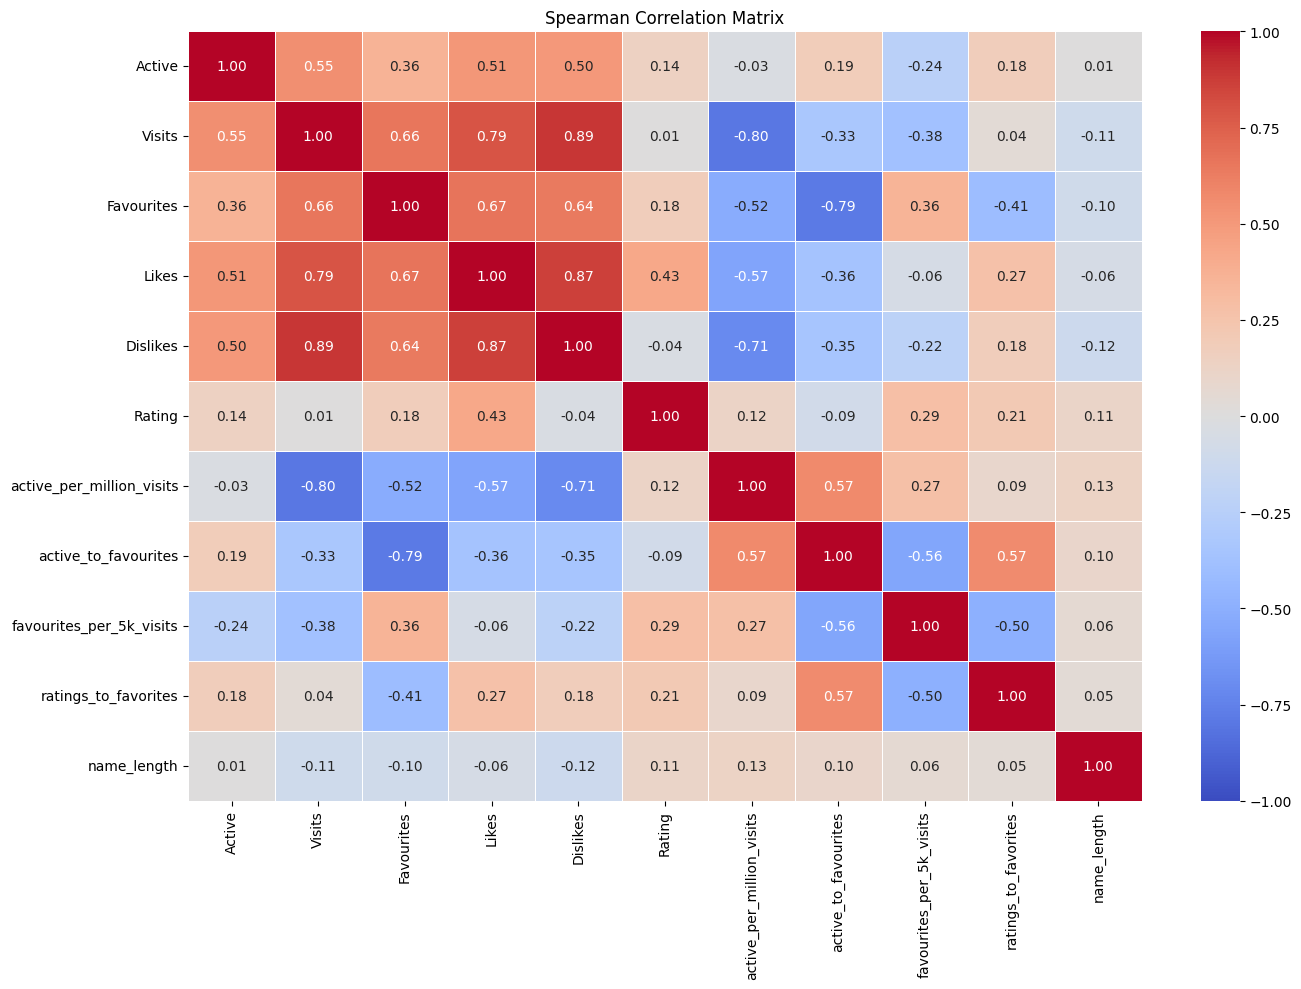

In [286]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_columns = [
    'Active',
    'Visits',
    'Favourites',
    'Likes',
    'Dislikes',
    'Rating',
    'active_per_million_visits',
    'active_to_favourites',
    'favourites_per_5k_visits',
    'ratings_to_favorites',
    'name_length'
]

correlation_matrix = filtered_df[correlation_columns].select_dtypes(
    include='number'
).corr(method='spearman')

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title('Spearman Correlation Matrix')
plt.tight_layout()
plt.show()

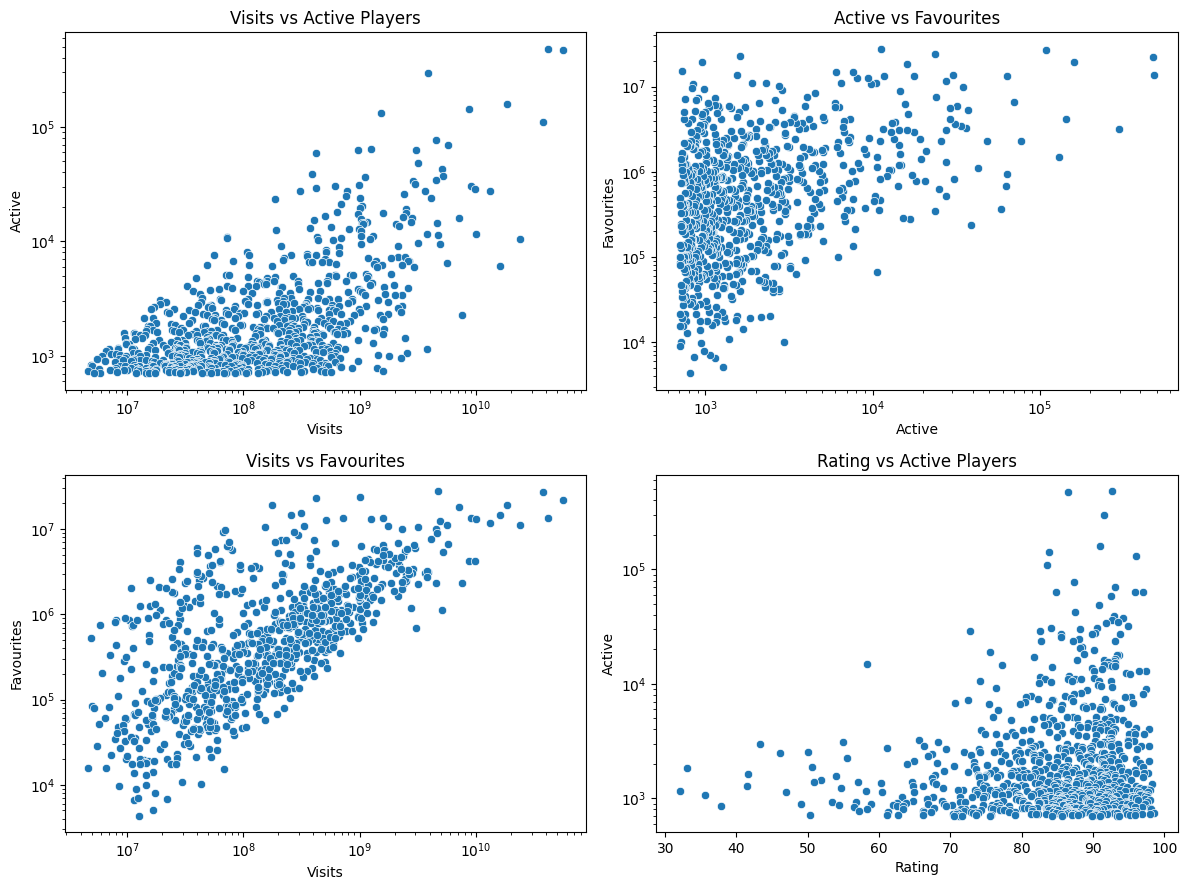

In [287]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.scatterplot(data=filtered_df, x='Visits', y='Active', ax=axes[0, 0])
axes[0, 0].set(xscale='log', yscale='log', title='Visits vs Active Players')

sns.scatterplot(data=filtered_df, x='Active', y='Favourites', ax=axes[0, 1])
axes[0, 1].set(xscale='log', yscale='log', title='Active vs Favourites')

sns.scatterplot(data=filtered_df, x='Visits', y='Favourites', ax=axes[1, 0])
axes[1, 0].set(xscale='log', yscale='log', title='Visits vs Favourites')

sns.scatterplot(data=filtered_df, x='Rating', y='Active', ax=axes[1, 1])
axes[1, 1].set(yscale='log', title='Rating vs Active Players')

plt.tight_layout()
plt.show()

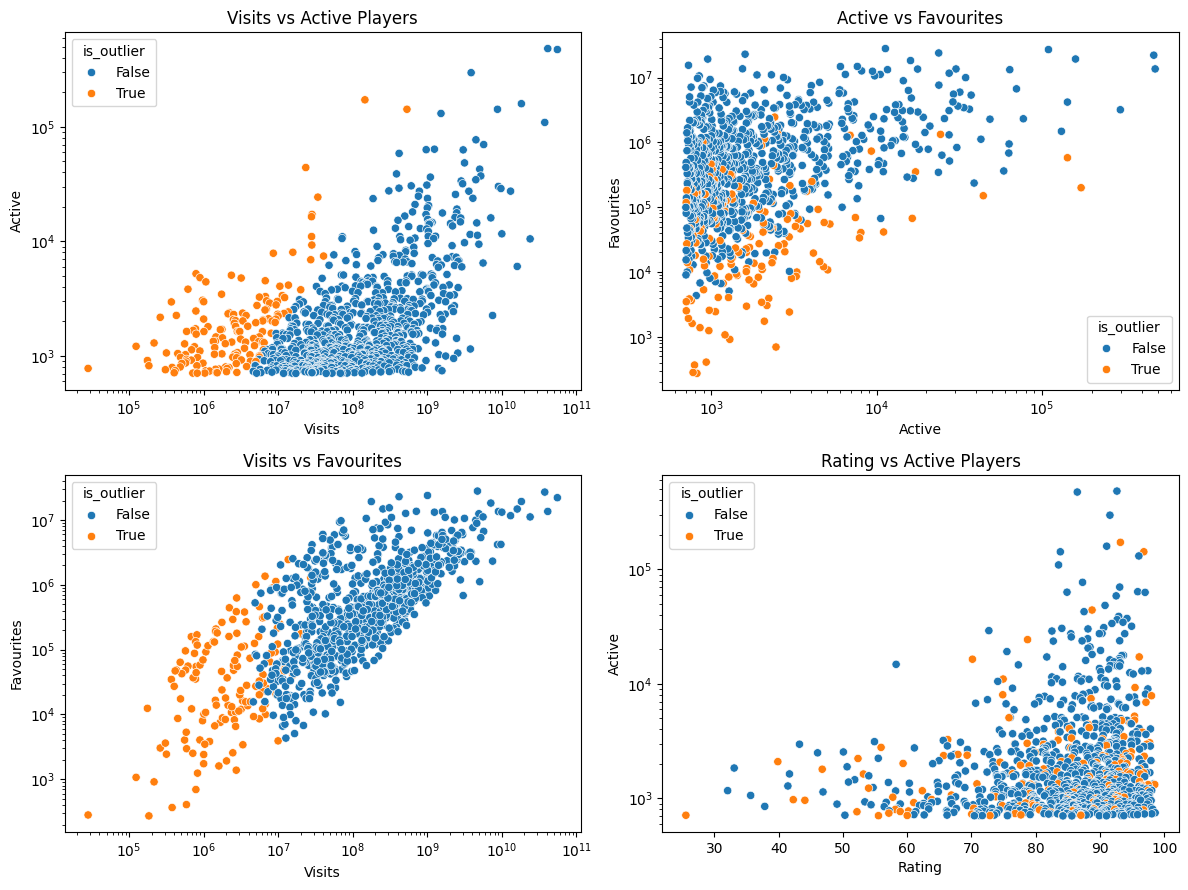

In [288]:
Q1 = cleaned_df['active_per_million_visits'].quantile(0.25)
Q3 = cleaned_df['active_per_million_visits'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

cleaned_df['is_outlier'] = ~cleaned_df['active_per_million_visits'].between(
    lower_bound, upper_bound
)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.scatterplot(data=cleaned_df, x='Visits', y='Active',
                hue='is_outlier', ax=axes[0, 0])
axes[0, 0].set(xscale='log', yscale='log',
              title='Visits vs Active Players')

sns.scatterplot(data=cleaned_df, x='Active', y='Favourites',
                hue='is_outlier', ax=axes[0, 1])
axes[0, 1].set(xscale='log', yscale='log',
              title='Active vs Favourites')

sns.scatterplot(data=cleaned_df, x='Visits', y='Favourites',
                hue='is_outlier', ax=axes[1, 0])
axes[1, 0].set(xscale='log', yscale='log',
              title='Visits vs Favourites')

sns.scatterplot(data=cleaned_df, x='Rating', y='Active',
                hue='is_outlier', ax=axes[1, 1])
axes[1, 1].set(yscale='log',
              title='Rating vs Active Players')

plt.tight_layout()
plt.show()

## Observations – Correlation Analysis

### 1. Game popularity and exposure

Visits are strongly correlated with likes (+0.79) and dislikes (+0.89), but barely correlated with rating (+0.01).

This suggests that greater exposure is associated with more rating activity, but not necessarily better reception.

### 2. Name length

Name length has negligible correlations with most of the numerical variables.

Its most notable relationship is with `Rating`, at approximately 0.11, which is still very weak.

This suggests that game name length provides little indication of a game's popularity, current activity or player reception within this dataset.

### 3. Visits vs Active Players

The number of Active players seems to be bound by the number of Visits, where games with a lot of visits can have few active players, but not vice versa.

This is most likely due to us excluding games are outliers with respect to active_per_million visits, since when adding them back in they exclusively occupy the left side of the boundary.

### 4. Visits vs Favourites

The number of Favourites is bounded below depending on the number of Visits, which holds even after we add the outliers back in. This means that games can have disproportionally more Favourites than Visits, but not thee other way round.

Combined with the fact that a similar effect is seen in the Active vs Favourites graph, it indicates the players are unlikely to visit games often without favouriting them, but don't unfavourite games when they stop playing them.


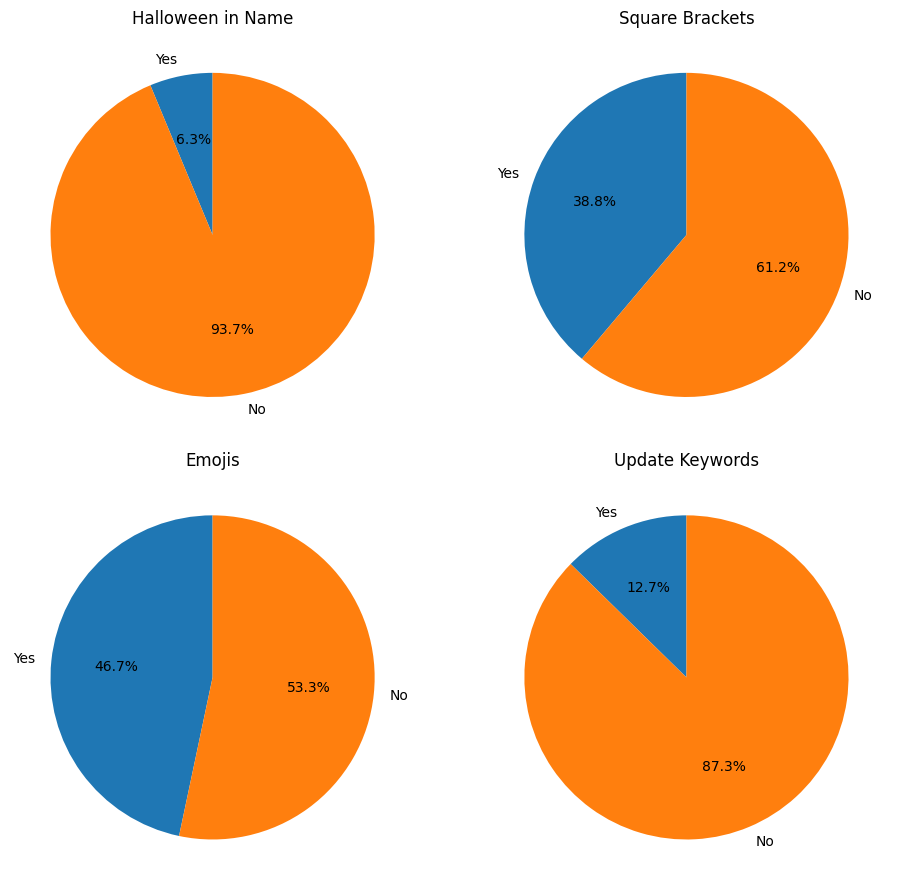

In [289]:
features = {
    'is_halloween': 'Halloween in Name',
    'has_square_brackets': 'Square Brackets',
    'has_emoji': 'Emojis',
    'has_update_keyword': 'Update Keywords'
}

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
axes = axes.flatten()

for (feature, title), ax in zip(features.items(), axes):
    counts = filtered_df[feature].value_counts().reindex(
        [True, False], fill_value=0
    )
    ax.pie(
        counts,
        labels=['Yes', 'No'],
        autopct='%1.1f%%',
        startangle=90
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

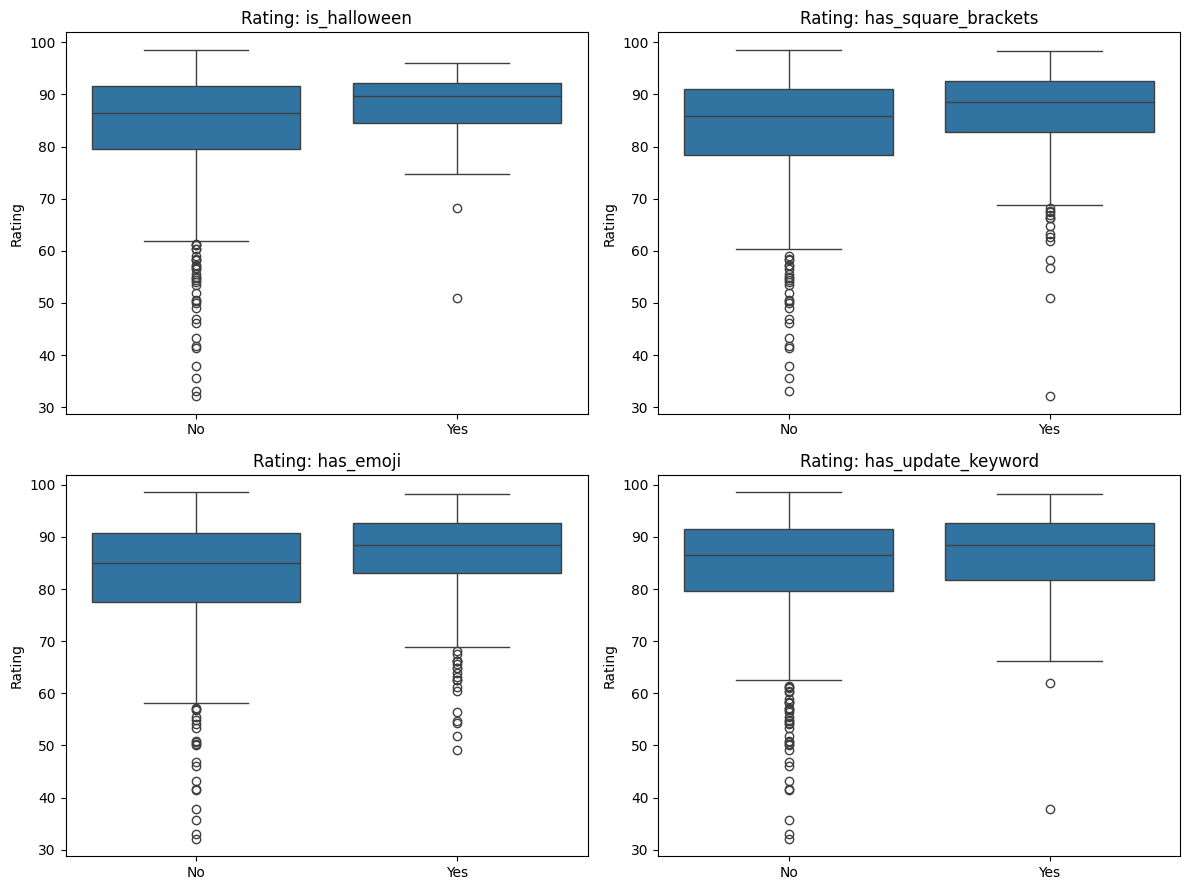

In [291]:
features = [
    'is_halloween',
    'has_square_brackets',
    'has_emoji',
    'has_update_keyword'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for feature, ax in zip(features, axes):
    sns.boxplot(
        data=filtered_df,
        x=feature,
        y='Rating',
        ax=ax
    )

    ax.set_title(f'Rating: {feature}')
    ax.set_xticks([0, 1], labels=['No', 'Yes'])
    ax.set_xlabel('')
    ax.set_ylabel('Rating')

plt.tight_layout()
plt.show()

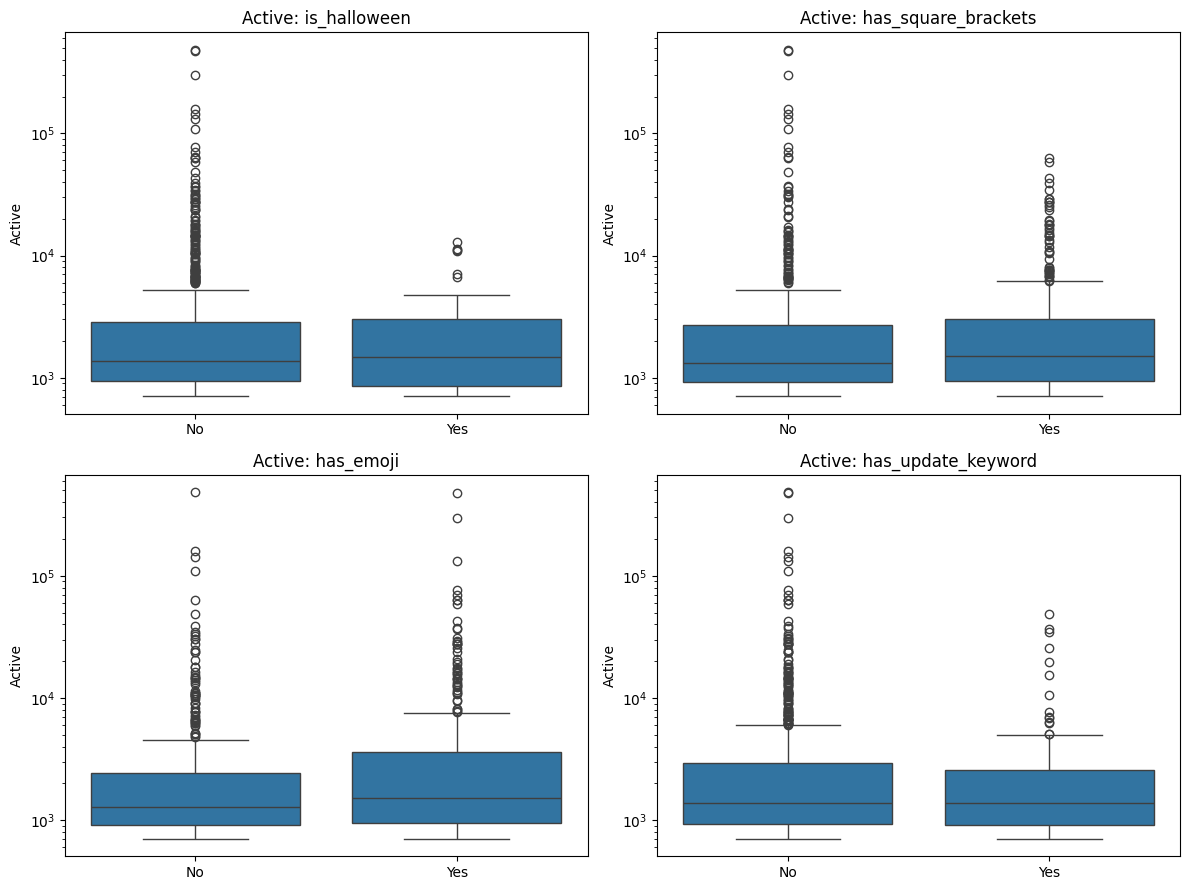

In [293]:
features = [
    'is_halloween',
    'has_square_brackets',
    'has_emoji',
    'has_update_keyword'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for feature, ax in zip(features, axes):
    sns.boxplot(
        data=filtered_df,
        x=feature,
        y='Active',
        ax=ax
    )

    ax.set_title(f'Active: {feature}')
    ax.set_xticks([0, 1], labels=['No', 'Yes'])
    ax.set_yscale('log')
    ax.set_xlabel('')
    ax.set_ylabel('Active')

plt.tight_layout()
plt.show()

In [298]:
from scipy.stats import mannwhitneyu

print("Significance of name features on Active player count: \n")
for feature in features:
    yes = filtered_df.loc[filtered_df[feature], 'Active'].dropna()
    no = filtered_df.loc[~filtered_df[feature], 'Active'].dropna()

    statistic, p_value = mannwhitneyu(yes, no, alternative='two-sided')

    print(f'{feature}: p-value = {p_value:.4f}')
print("")

print("Significance of name features on Rating: \n")
for feature in features:
    yes = filtered_df.loc[filtered_df[feature], 'Rating'].dropna()
    no = filtered_df.loc[~filtered_df[feature], 'Rating'].dropna()

    statistic, p_value = mannwhitneyu(yes, no, alternative='two-sided')

    print(f'{feature}: p-value = {p_value:.4f}')

Significance of name features on Active player count: 

is_halloween: p-value = 0.7437
has_square_brackets: p-value = 0.1471
has_emoji: p-value = 0.0220
has_update_keyword: p-value = 0.7464

Significance of name features on Rating: 

is_halloween: p-value = 0.0443
has_square_brackets: p-value = 0.0000
has_emoji: p-value = 0.0000
has_update_keyword: p-value = 0.0645


In [301]:
for feature in features:
    print(f'\n{feature}')

    print(
        filtered_df.groupby(feature)
        .agg(
            count=('Rating', 'count'),
            mean_rating=('Rating', 'mean'),
            std_rating=('Rating', 'std'),
            mean_active=('Active', 'mean'),
            std_active=('Active', 'std')
        ).round(3)
    )


is_halloween
              count  mean_rating  std_rating  mean_active  std_active
is_halloween                                                         
False           777       84.212      10.605     6148.874   29029.140
True             52       87.250       7.827     2666.000    2969.431

has_square_brackets
                     count  mean_rating  std_rating  mean_active  std_active
has_square_brackets                                                         
False                  507       83.078      11.277     7129.278   35413.549
True                   322       86.488       8.685     4042.742    7593.357

has_emoji
           count  mean_rating  std_rating  mean_active  std_active
has_emoji                                                         
False        442       82.509      11.517     5210.215   26125.658
True         387       86.564       8.662     6752.951   30261.102

has_update_keyword
                    count  mean_rating  std_rating  mean_active  std_active
ha